# Learning CLEVR concepts from answers only (E1)

**The problem.** CLEVR scenes are rendered images of 3 to 10 objects. Each object has four **attributes** (a colour among 8, a size among 2, a material among 2, a shape among 3), and pairs of objects stand in four **spatial relations** (left, right, in front, behind). Each question about a scene comes with a **program**, and the questions built from the same program template form a **family**. The notebook `e0_perfect_sight.ipynb` (E0) turned every in-scope family into one sLTN formula, and showed that with the true attributes and relations ("perfect sight") the formulas reproduce all the dataset's answers.

Here the attributes and the relations are not given. Networks must learn to **see** them, and the only training signal is the **answers** to the questions, through the same formulas. No attribute or relation label is ever used in training; the scene files' labels are used only to score the networks at the end.

**Why answers can teach the networks.** For a question, sLTN evaluates its family's rule, "the question's formula is true exactly when the dataset's answer says so", on the networks' outputs. The rule can be satisfied only if the networks read the scene correctly: *"What color is the matte thing in front of the large cube? → cyan"* holds only if some object read as a large cube has, in front of it, a rubber object read as cyan. Each word is tied to one output neuron: "red" always reads the same output of the colour network and "left" the same output of the relation network, in every question and every answer. So the networks can't learn the colours or relations under swapped names, as they could if only the rules' structure constrained them.

**How the experiment is built, step by step.** Each step removes one thing that was given:

| Step | Objects seen as | Attributes | Relations | Trained on | Where |
|---|---|---|---|---|---|
| Step 0 | invented feature vectors | learned | given | all in-scope questions | CPU, minutes |
| Step 1 | perfect sight | given | learned | the questions with a relation | CPU, minutes |
| Run 1 | image crops | learned | given | all in-scope questions | GPU, about 1 hour |
| Run 2 | image crops | learned | learned | all in-scope questions | GPU, about 1 hour |
| Run 3 | image crops | learned | learned | only the questions with a relation | GPU, about 1 hour |

- **Step 0** controls how hard the objects are to read (feature noise) and compares with the same networks trained *with* attribute labels.
- **Step 1** checks that answers can teach the relations, before mixing them with images.
- **Runs 1–3** are the real setting, from images. Run 3 removes the questions that would teach the attributes alone ("Is there a red cube?"): every training question involves a spatial relation, so attributes and relations can only be learned together. The families it doesn't train on are then questions never seen in training.

**The model in words.**
- **Attributes:** a small CNN reads one crop per object (a square cut around the object's position in the image) and outputs four probability distributions: over the 8 colours, the 2 sizes, the 2 materials, the 3 shapes.
- **Relations** (step 1, runs 2–3): a small network reads the positions of two objects (horizontal and vertical pixel position, and depth) and outputs four probabilities: is the second object left of, right of, in front of, behind the first.
- **Knowledge:** the rules of E0's 56 formulas, unchanged. Training maximises their satisfaction on batches of questions.

**What is given and what is learned.**

- **Given:** where each object is (pixel position and depth) and, in runs 1–3, the crop cut there; each question's program; each question's answer.
- **Learned:** the attributes (all steps but 1) and the relations (step 1, runs 2–3).
- **Never used in training, only to score:** the attribute labels and the relation labels.

**Comparison.** In step 0, the same networks trained with cross-entropy on the attribute labels: an upper bound for what the features allow. For the images, E0 is the reference: with perfect concepts, the formulas answer every question correctly.

**What this example shows:**
- **Classifiers learned with no labels on them.** The four attribute classifiers and the relation classifier learn only from answers to logical questions about the objects.
- **Networks inside the formulas.** The formulas are E0's; only the groundings change, from the scene file's values to the networks' outputs.
- **A constant grounded with a network's output.** `x[q, o]` is the CNN's embedding of each object's crop, recomputed at every step; gradients flow through it to the CNN.
- **A learned structural relation.** `R0`, `R1`, ... are grounded with the relation network's output for the direction each question names.
- **Several networks trained through one knowledge base.** The CNN and the relation network are trained together by the same rules.
- **Question families never trained on.** In run 3, the families without a spatial relation are answered at test time by composing what was learned from the others.

**Compute.** This notebook doesn't train: it reads the saved results (in `results/`) and runs the trained networks on a few validation images, on CPU, in under a minute. The training scripts are named in each section.

**Data.** [CLEVR](https://cs.stanford.edu/people/jcjohns/clevr/) (Johnson et al., CVPR 2017), licensed CC BY 4.0. The first run downloads the scene and question files (`CLEVR_v1.0_no_images.zip`, 85 MB) into `notebooks/datasets/`. The images are only in the full 18 GB archive, so the 12 validation images this notebook shows are included in `images/`.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

sys.path.insert(0, str(Path.cwd().resolve()))   # notebooks/examples/CLEVR
from clevr_sltn import ATTRS, DATA, DIRS, IMAGES, RESULTS, VALUES, O, download
from e1_images import ConceptNet, RelationNet, positions
from prep_crops import K as CROP_K, R as CROP_R, crops_of

download()                                      # CLEVR's scene and question files (85 MB), the first time
RUNS = {"run 1": "e1_images_seed0.log", "run 2": "e1_images_relations_seed0.log", "run 3": "e1_images_relq_seed0.log"}
COLORS = {"color": "#2a78d6", "size": "#eb6834", "material": "#1baf7a", "shape": "#7d5fd3",
          "left": "#2a78d6", "right": "#eb6834", "front": "#1baf7a", "behind": "#7d5fd3"}


def read_run(name):
    # the training curve (from the log) and the final results (results.json) of a GPU run, or None
    log = RESULTS / "e1" / "logs" / RUNS[name]
    if not log.exists():
        return None
    text = log.read_text()
    curve = []
    for m in re.finditer(r"^step\s+(\d+) loss ([\d.]+) \| [^:]+: (.*) \| (\d+) ms/step", text, re.M):
        row = dict(step=int(m[1]), loss=float(m[2]))
        row.update({k: float(v) for k, v in (p.split() for p in m[3].split(", "))})
        curve.append(row)
    saved = re.search(r"saved (\S+);", text)
    if saved is None:
        return dict(curve=curve, final=None)
    final = json.loads((RESULTS / "e1" / Path(saved[1]).name / "results.json").read_text())
    return dict(curve=curve, final=final, dir=RESULTS / "e1" / Path(saved[1]).name)


def plot_curve(run, names, title, ax):
    steps = [r["step"] for r in run["curve"]]
    for n in names:
        ax.plot(steps, [r[n] for r in run["curve"]], label=n, color=COLORS[n], lw=1.8)
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_xlabel("training step")
    ax.set_ylim(0.9, 1.002)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")


def final_table(run):
    f = run["final"]
    rows = [("attribute accuracy (all val objects)", {a: f[f"concept_acc/{a}"] for a in ATTRS})]
    if "relation_acc/left" in f:
        rows.append(("relation accuracy (all val pairs)", {d: f[f"relation_acc/{d}"] for d in DIRS}))
    rows.append(("QA accuracy (101,028 val questions)", {"all": f["qa_acc"], **{k[len("qa_acc/"):]: v for k, v in f.items() if k.startswith("qa_acc/")}}))
    for title, vals in rows:
        print(f"{title}:")
        print("   " + "   ".join(f"{k} {v:.4f}" for k, v in vals.items()))

## 1. What changes from E0

The signature, the 56 formulas and the rules are E0's (`clevr_sltn.py`). Only the groundings change:

| Symbol | E0 (perfect sight) | E1 |
|---|---|---|
| `x[q, o]` | the object's four attributes, one-hot (15 numbers) | the CNN's **embedding** of the object's crop (256 numbers), recomputed at every training step; zeros for an empty position |
| `color`, `size`, `material`, `shape` | read the attribute's slice of `x` | the CNN's four **heads**: a linear layer and a softmax on the embedding |
| `IsC`, ... | dot product | dot product, clamped to [0, 1] (with an all-ones filter value, the sum of a softmax can come out as 1.0000001, which isn't a truth value) |
| `R0`, `R1`, ... | CLEVR's adjacency for the direction the question names | runs 1 and step 0: the same; step 1, runs 2–3: the **relation network's** output for that direction |
| `Present`, `Neq`, filter values, ground truth | from the scene file and the question | the same |

**One training step:**
1. pick 8 families (the larger a family, the more often it is picked) and sample 80 questions from each, 640 per step. Steps 0 and 1 sample 64 per family, 512 per step;
2. run the CNN once on every real object of those questions' scenes, and the relation network on every pair of objects (runs 2–3);
3. ground each family's symbols and evaluate its rule; loss = 1 − the mean satisfaction of the 8 rules;
4. one Adam step (learning rate 10⁻³) on the networks' weights.

**Scores**, always on the validation split, which training never sees: **attribute accuracy** on every real object (the most probable value against the scene file); **relation accuracy** on every ordered pair of distinct objects (probability above 0.5 against CLEVR's adjacency); **QA accuracy** on the 101,028 in-scope questions, each answered by its family's formula on the networks' outputs, as in E0.

## 2. Step 0: invented features

Before images, a controlled version (`e1_features.py`, `e1_features_sweep.py`; CPU). Each object gets a feature vector made from its true attributes:
- every value of every attribute has a fixed random vector of 16 numbers ("red" one vector, "cube" another, ...);
- an object's feature is its four vectors concatenated (64 numbers), mixed by a fixed random rotation, so that no single number carries one attribute. The rotation only hides which numbers carry which attribute: a network can undo it;
- plus Gaussian noise with standard deviation `noise`, fixed per object: this is what makes the attributes hard to read. The two closest values of an attribute are 4 to 5 apart (colour 3.9, shape 4.3, size 4.7, material 5.4), so at noise 2–3 their noisy features overlap: even the best possible classifier reads only 68% (noise 2) and 48% (noise 3) of the colours right (the *best possible* rows of the table below).

Four small networks (64 → 64 → the attribute's values, softmax) replace perfect sight, trained for 1,000 steps from the answers. The reference is the same networks trained for 1,000 steps on the **attribute labels** of the objects of the same training scenes. The training questions are the first 3,000 or 30,000 of the training file, of which about two thirds are in scope.

In [2]:
from e1_features import EMB

sweep = json.loads((RESULTS / "e1_features" / "sweep_results.json").read_text())
g = torch.Generator().manual_seed(1000 + sweep["seed"])     # the sweep's value vectors (e1_features_sweep.py)
emb = {a: torch.randn(len(VALUES[a]), EMB, generator=g) for a in ATTRS}


def best_possible(noise, n=200_000):
    # Accuracy of reading each object as its nearest value: the best any network can do, since the noise is
    # Gaussian and the same in every direction and the values are equally likely. The rotation doesn't change it.
    g = torch.Generator().manual_seed(0)
    acc = {}
    for a in ATTRS:
        y = torch.randint(0, len(emb[a]), (n,), generator=g)
        x = emb[a][y] + noise * torch.randn(n, EMB, generator=g)
        acc[a] = float((torch.cdist(x, emb[a]).argmin(1) == y).float().mean())
    return acc


print(f"{'noise':>5s} {'questions':>9s} {'trained on':>13s} | " + " ".join(f"{a:>8s}" for a in ATTRS) + " | QA (val)")
for noise in sorted({r["noise"] for r in sweep["rows"]}):
    for r in (r for r in sweep["rows"] if r["noise"] == noise):
        print(f"{r['noise']:5.1f} {r['n_questions']:9d} {('answers' if r['model'] == 'sltn' else 'labels'):>13s} | "
              + " ".join(f"{r[a]:8.3f}" for a in ATTRS) + f" | {r['qa']:.3f}")
    b = best_possible(noise)
    print(f"{noise:5.1f} {'':9s} {'best possible':>13s} | " + " ".join(f"{b[a]:8.3f}" for a in ATTRS) + " |")

noise questions    trained on |    color     size material    shape | QA (val)
  1.0      2045       answers |    0.928    0.982    0.994    0.979 | 0.931
  1.0      2045        labels |    0.939    0.986    0.994    0.981 | 0.940
  1.0     20250       answers |    0.955    0.988    0.995    0.984 | 0.954
  1.0     20250        labels |    0.960    0.990    0.996    0.986 | 0.957
  1.0           best possible |    0.965    0.991    0.997    0.988 |
  2.0      2045       answers |    0.226    0.680    0.633    0.451 | 0.469
  2.0      2045        labels |    0.577    0.843    0.884    0.809 | 0.631
  2.0     20250       answers |    0.637    0.866    0.899    0.823 | 0.663
  2.0     20250        labels |    0.661    0.864    0.897    0.831 | 0.654


  2.0           best possible |    0.680    0.880    0.912    0.845 |
  3.0      2045       answers |    0.151    0.631    0.562    0.356 | 0.451
  3.0      2045        labels |    0.351    0.721    0.759    0.635 | 0.516
  3.0     20250       answers |    0.228    0.613    0.696    0.492 | 0.472
  3.0     20250        labels |    0.456    0.757    0.791    0.685 | 0.543
  3.0           best possible |    0.484    0.784    0.816    0.708 |


- **Readable features (noise 1): answers teach as much as labels.** With 2,045 questions the gap is about one point; with 20,250 it is under half a point.
- **Noisier features need more answers.** At noise 2, 20,250 questions match the labels; 2,045 don't.
- **At noise 3, learning from answers stalls** within 1,000 steps (colour 0.23 vs 0.46 with labels). An answer constrains several objects and attributes at once, so it carries less information about one object than its label does.
- With noise 0.5 (a first run, 200 steps on about 20,000 questions), the networks reached 100% on all four attributes.

One seed, 1,000 steps: these are trends, not precise numbers.

## 3. Step 1: relations alone

Before mixing relations with images, a check that answers can teach the relations (`e1_relations_perfect_sight.py`; CPU). The attributes come from perfect sight, as in E0; only the **relation network** learns.

- **Input:** the positions of two objects: pixel x / 480, pixel y / 320 and depth / 15, from the scene file (the same positions used to cut the crops).
- **Network:** a small MLP (9 numbers → 64 → 64 → 4, sigmoid). For a pair (o1, o2), its input is o1's position (x, y, depth), o2's position, and their difference o2 − o1, which says where o2 is relative to o1. The four relations depend only on that difference ("left" is roughly x(o2) − x(o1) < 0, "in front" roughly depth(o2) − depth(o1) < 0), so giving it explicitly makes them easy to learn; the absolute positions let the network correct where pixels and depth only approximate CLEVR's 3D definition. Its four outputs are four independent probabilities (a pair can be both left and behind): that o2 is left of, right of, in front of, behind o1.
- **Grounding:** the question chooses the direction, not the network. A question's relate `k` names one direction ("the thing *in front of* the small metal object"), and `Rk(q, o1, o2)` is grounded with the network's output for that direction, for every pair of objects: a soft O × O matrix, with no argmax and no threshold (the 0.5 threshold only scores relation accuracy). The other three outputs aren't used by that question. A direction always reads the same output (*front* is always output 2), so the words anchor the outputs, as for the attributes.
- **Training:** only the 31 families with a relate (the others don't involve the relations), the first 30,000 training questions (10,563 of them in those families), 600 steps.

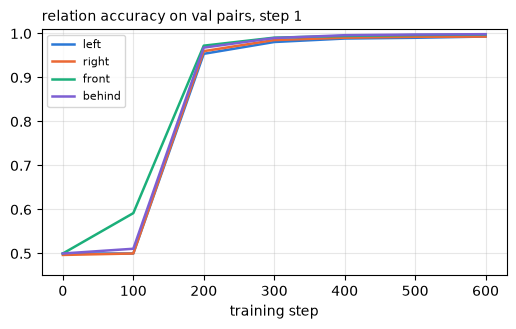

final relation accuracy (all val pairs): left 0.9929, right 0.9930, front 0.9976, behind 0.9984
QA accuracy (val, perfect attributes + learned relations): 0.9990
   compare          1.0000
   compare+relate   0.9962
   exist            1.0000
   exist+relate     0.9957
   query            1.0000
   query+relate     0.9999


In [3]:
rel = json.loads((RESULTS / "e1_relations_perfect_sight" / "results.json").read_text())
fig, ax = plt.subplots(figsize=(6, 3.2))
steps = [h["step"] for h in rel["history"]]
for d in DIRS:
    ax.plot(steps, [h[d] for h in rel["history"]], label=d, color=COLORS[d], lw=1.8)
ax.set_title("relation accuracy on val pairs, step 1", fontsize=10, loc="left")
ax.set_xlabel("training step"); ax.set_ylim(0.45, 1.01); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
print("final relation accuracy (all val pairs): " + ", ".join(f"{d} {v:.4f}" for d, v in rel["relation_acc"].items()))
print(f"QA accuracy (val, perfect attributes + learned relations): {rel['qa']:.4f}")
for k, v in rel["qa_by_type"].items():
    print(f"   {k:16s} {v:.4f}")

The network starts at chance (0.5) and, after a short flat phase, learns all four directions. Nothing told it which of its four outputs is "left", or what "left" means in terms of positions: both come from the answers, through the questions that say "left".

## 4. From images: one crop per object

The images are 480 × 320 pixels. The scene file gives each object's position in the image (`pixel_coords`: x, y and depth), not a bounding box. `prep_crops.py` cuts, once for the whole dataset, a square around each object:
- **half-side = K / depth pixels** (K = 500): a far object looks smaller, so its square is smaller. After resizing every square to 48 × 48 pixels, objects have about the same scale whatever their distance, and a large object fills the crop while a small one fills about half of it: size stays visible.
- Empty positions (scenes with fewer than 10 objects) get a black crop, which the CNN never sees: the CNN runs only on real objects.

Crops of three validation scenes, with the attributes the CNN must learn (from the scene file, not used in training):

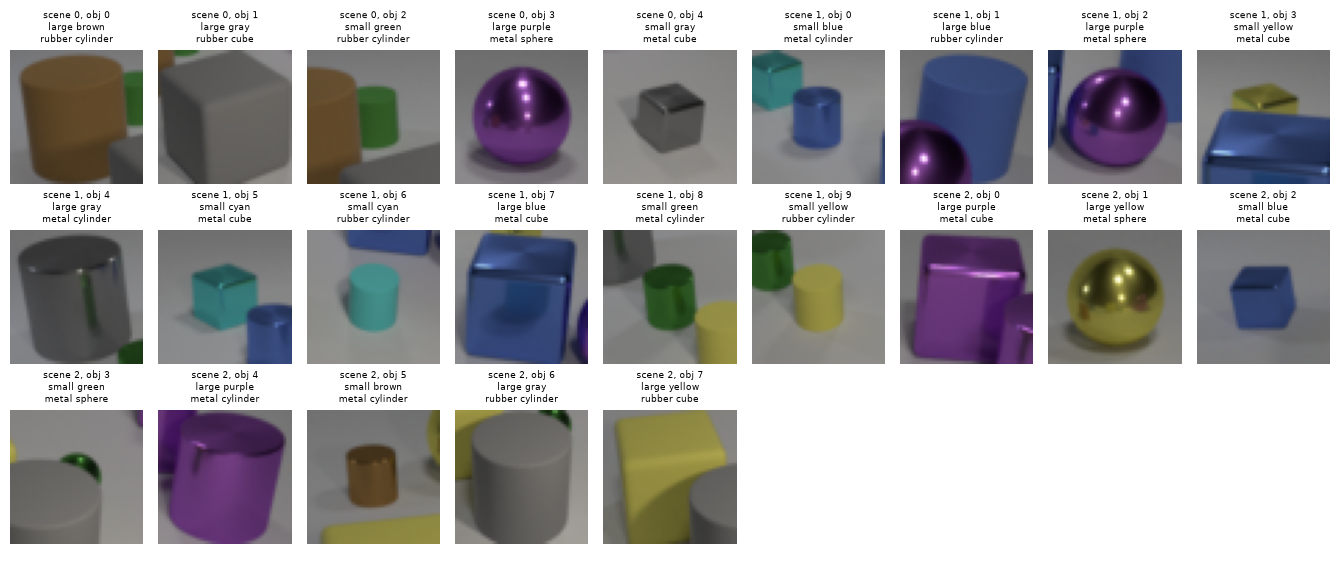

crop: half-side 500 / depth pixels, resized to 48 x 48


In [4]:
scenes = json.load(open(DATA / "scenes" / "CLEVR_val_scenes.json"))["scenes"]
local = sorted(int(p.stem[-6:]) for p in IMAGES.glob("CLEVR_val_*.png"))   # the 12 images included in images/
show = local[:3]
objs = [(s, i) for s in show for i in range(len(scenes[s]["objects"]))]
crops = {s: crops_of((IMAGES / scenes[s]["image_filename"], scenes[s]["objects"])) for s in local}
cols = 9
fig, axs = plt.subplots((len(objs) + cols - 1) // cols, cols, figsize=(cols * 1.5, 1.9 * ((len(objs) + cols - 1) // cols)))
for ax in axs.flat:
    ax.axis("off")
for ax, (s, i) in zip(axs.flat, objs):
    ob = scenes[s]["objects"][i]
    ax.imshow(crops[s][i])
    ax.set_title(f"scene {s}, obj {i}\n{ob['size']} {ob['color']}\n{ob['material']} {ob['shape']}", fontsize=6.5)
plt.tight_layout()
plt.show()
print(f"crop: half-side {CROP_K} / depth pixels, resized to {CROP_R} x {CROP_R}")

The crops show the object in the middle, and sometimes parts of its neighbours; an object can even be mostly hidden (scene 2, object 3: a small green metal sphere behind a gray cylinder). The CNN has to learn to read the object in the middle.

## 5. The networks and the training on images

`e1_images.py`, run on one NVIDIA A40 GPU:
- **ConceptNet** (the attributes): four convolutional blocks (each: two 3 × 3 convolutions with batch normalisation and ReLU, then a 2 × 2 max-pool; 64, 128, 128, 256 channels), global average pooling to a 256-number **embedding**, and four linear **heads** with a softmax. The embedding grounds `x[q, o]`; each head grounds one attribute function.
- **RelationNet** (runs 2–3): the network of step 1.
- **Training:** 4,500 steps of 8 families × 80 questions, from all 471,489 in-scope training questions (run 3: only those of the 31 families with a relate), Adam with learning rate 10⁻³, seed 0. About 0.7 s per step, 55 minutes per run.

In [5]:
net, relnet = ConceptNet(), RelationNet()
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"ConceptNet: {n_params(net):,} parameters (trunk {n_params(net.trunk):,}, heads {n_params(net.heads):,})")
print(f"RelationNet: {n_params(relnet):,} parameters")

ConceptNet: 1,446,735 parameters (trunk 1,442,880, heads 3,855)
RelationNet: 5,060 parameters


## 6. Run 1: images, relations given

The CNN learns the attributes; the relations are CLEVR's, as in E0. Curves: attribute accuracy on 2,000 validation scenes every 250 steps.

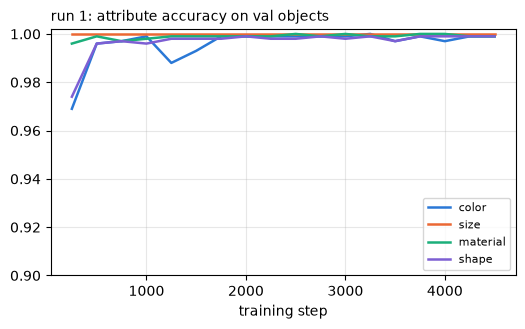

attribute accuracy (all val objects):
   color 0.9991   size 1.0000   material 0.9993   shape 0.9994
QA accuracy (101,028 val questions):
   all 0.9988   exist 0.9987   query 0.9994   compare 0.9977


In [6]:
run1 = read_run("run 1")
fig, ax = plt.subplots(figsize=(6, 3.2))
plot_curve(run1, ATTRS, "run 1: attribute accuracy on val objects", ax)
plt.show()
final_table(run1)

- The attributes are learned almost at once: above 96% at step 250, above 99.6% at step 500. The remaining steps polish them.
- With the learned attributes, the formulas answer 99.9% of the validation questions. With perfect sight (E0) they answer 100%, so almost every error left comes from a misread attribute.
- Compare-attribute questions ("Is the cube the same size as the sphere?") are answered at 99.8%. On these, every neural model of the CLEVR paper is at chance (49–55%); the comparison is not like for like (those models learn from pixels and English, with no object positions and no programs given), but it shows what the programs and the formulas bring.

## 7. Run 2: images, attributes and relations learned together

The CNN and the relation network are trained together, from the answers only.

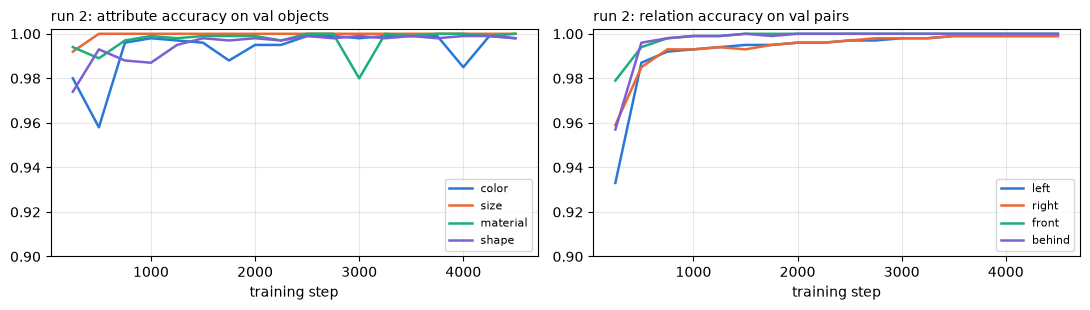

attribute accuracy (all val objects):
   color 0.9990   size 1.0000   material 0.9997   shape 0.9980
relation accuracy (all val pairs):
   left 0.9994   right 0.9994   front 0.9999   behind 1.0000
QA accuracy (101,028 val questions):
   all 0.9981   exist 0.9977   query 0.9987   exist+relate 0.9982   compare 0.9978   query+relate 0.9994   compare+relate 0.9961


In [7]:
run2 = read_run("run 2")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
plot_curve(run2, ATTRS, "run 2: attribute accuracy on val objects", axs[0])
plot_curve(run2, DIRS, "run 2: relation accuracy on val pairs", axs[1])
axs[1].set_ylim(0.9, 1.002)
plt.tight_layout()
plt.show()
final_table(run2)

- Both networks learn from the first hundreds of steps: at step 250 the relations are at 93–98% and the attributes at 97–99%; at step 750 everything is above 99%.
- Final scores are those of run 1: learning the relations costs nothing in QA (99.81% vs 99.88%).
- A first explanation was that about half of the training questions (48%, 227,956 of 471,489) have no spatial relation ("Is there a red cube?", "What size is the metal sphere?"), so they could teach the attributes first, as in run 1, and the relation questions would then teach the relations, as in step 1. Run 3 tests this by removing those questions.

## 8. Run 3: relation questions only

The same as run 2, but trained only on the 31 families whose program has a relate, for example *"There is a small gray block; are there any spheres to the left of it?"* or *"What color is the matte thing in front of the large cube?"*. Every training question involves a spatial relation, so the CNN gets a signal only through the relation network's output, and the other way round. The 29 families without a relate (25 formulas, since some of them share one; *"Is there a red cube?"*, *"Is the cylinder the same size as the sphere?"*, *"Is there another block with the same color as the tiny cube?"*) are never trained on; their QA accuracy (the rows without "+relate") measures questions never seen in training.

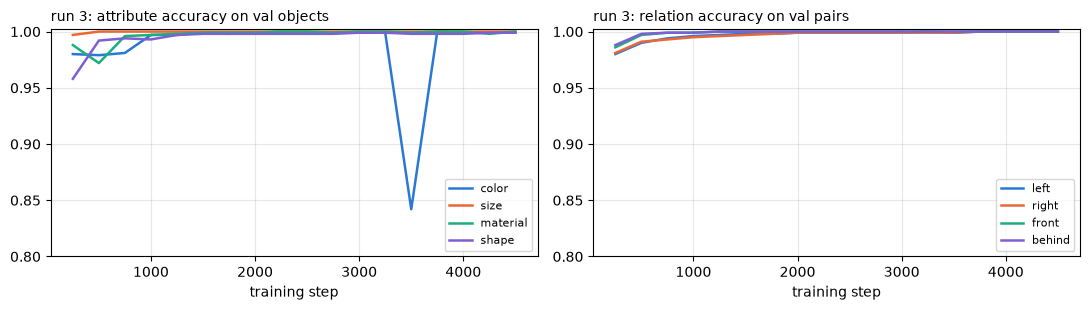

attribute accuracy (all val objects):
   color 0.9993   size 1.0000   material 0.9996   shape 0.9993
relation accuracy (all val pairs):
   left 0.9997   right 0.9998   front 1.0000   behind 1.0000
QA accuracy (101,028 val questions):
   all 0.9991   exist 0.9993   query 0.9995   exist+relate 0.9994   compare 0.9981   query+relate 0.9997   compare+relate 0.9980


In [8]:
run3 = read_run("run 3")
if run3 is None or run3["final"] is None:
    print("run 3 has not finished yet")
else:
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
    plot_curve(run3, ATTRS, "run 3: attribute accuracy on val objects", axs[0])
    plot_curve(run3, DIRS, "run 3: relation accuracy on val pairs", axs[1])
    for ax in axs:
        ax.set_ylim(0.8, 1.002)
    plt.tight_layout()
    plt.show()
    final_table(run3)

- **Attributes and relations are learned as well as in run 2, and as fast.** At step 250 the attributes are at 96–100% and the relations at 98–99% (run 2: 93–98%); at the end, attributes 99.9–100% and relations 99.97–100%. So the questions without a spatial relation were not needed: the first explanation of run 2 was wrong. Every relation question constrains attributes and relations together, and the many different questions about different scenes are enough to pull both apart.
- **The 29 families never trained on are answered as well as the trained ones:** exist 99.93%, query 99.95%, compare 99.81%, against 99.94%, 99.97%, 99.80% for the families with a relate. The networks learned concepts, not families: a new question is answered by composing them in its formula.
- One dip, colour at 84% at step 3,500, recovered by the next evaluation (fixed learning rate; the final networks are those of step 4,500).

## 9. The trained networks on a few validation scenes

The networks of run 2, loaded on CPU, on the 12 validation images included in `images/`: the CNN's reading of every object, and the relation network's reading of every pair.

In [9]:
d = read_run("run 2")["dir"]
net = ConceptNet(); net.load_state_dict(torch.load(d / "concept_net.pt", map_location="cpu")); net.eval()
relnet = RelationNet(); relnet.load_state_dict(torch.load(d / "relation_net.pt", map_location="cpu")); relnet.eval()

wrong, total = [], 0
with torch.no_grad():
    for s in local:
        n = len(scenes[s]["objects"])
        probs = net(torch.from_numpy(crops[s][:n]))
        for i, ob in enumerate(scenes[s]["objects"]):
            pred = {a: VALUES[a][int(probs[a][i].argmax())] for a in ATTRS}
            total += 1
            if any(pred[a] != ob[a] for a in ATTRS):
                wrong.append((s, i, pred, {a: ob[a] for a in ATTRS}))
print(f"{len(local)} scenes, {total} objects: {total - len(wrong)} read entirely right")
for s, i, pred, true in wrong:
    print(f"   scene {s}, object {i}: read {pred}, true {true}")

pos = positions([scenes[s] for s in local])
with torch.no_grad():
    R = relnet(pos) > 0.5                                         # [scenes, 4, O, O]
hit = n_pairs = 0
for k, s in enumerate(local):
    n = len(scenes[s]["objects"])
    for di, dname in enumerate(DIRS):
        true = torch.zeros(O, O, dtype=torch.bool)
        for u, objs in enumerate(scenes[s]["relationships"][dname]):
            true[u, objs] = True
        mask = ~torch.eye(n, dtype=torch.bool)
        hit += int((R[k, di, :n, :n] == true[:n, :n])[mask].sum())
        n_pairs += int(mask.sum())
print(f"relations: {hit} of {n_pairs} (pair, direction) readings right")

12 scenes, 76 objects: 75 read entirely right
   scene 9, object 7: read {'color': 'blue', 'size': 'small', 'material': 'metal', 'shape': 'cylinder'}, true {'color': 'blue', 'size': 'small', 'material': 'metal', 'shape': 'cube'}
relations: 1831 of 1832 (pair, direction) readings right


The only object of these scenes the CNN misreads, and its crop: on these 12 validation images, the networks of run 2 read 75 of 76 objects entirely right and 1,831 of 1,832 relation readings right.

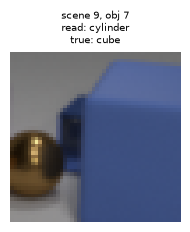

In [10]:
if wrong:
    fig, axs = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.4), squeeze=False)
    for ax, (s_w, i_w, pred, true) in zip(axs[0], wrong):
        ax.imshow(crops[s_w][i_w]); ax.axis("off")
        ax.set_title(f"scene {s_w}, obj {i_w}\nread: {pred['shape']}\ntrue: {true['shape']}", fontsize=7)
    plt.show()

The only relation reading of these scenes the relation network gets wrong (a probability on the wrong side of 0.5), with the network's four outputs for that pair:

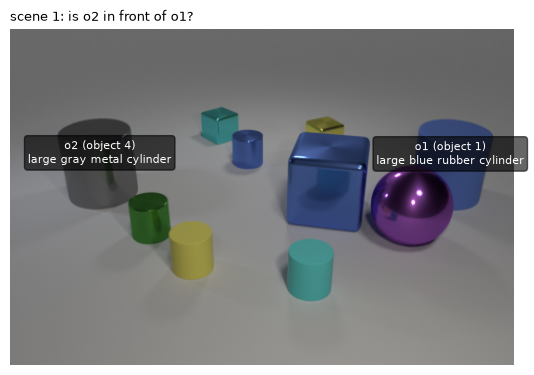

direction | network: P(o2 is direction of o1) | CLEVR
     left |                             1.000 | yes
    right |                             0.000 | no
    front |                             0.516 | no
   behind |                             0.925 | yes

positions (pixel x, pixel y, depth): o1 (419, 128, 11.16), o2 (85, 127, 11.20)


In [11]:
with torch.no_grad():
    P = relnet(pos)                                               # [scenes, 4, O, O]: probabilities
wrong_rel = []
for k, s in enumerate(local):
    n = len(scenes[s]["objects"])
    for di, dname in enumerate(DIRS):
        for o1 in range(n):
            for o2 in range(n):
                if o1 != o2 and (P[k, di, o1, o2] > 0.5) != (o2 in scenes[s]["relationships"][dname][o1]):
                    wrong_rel.append((k, s, dname, o1, o2))

for k, s, dname, o1, o2 in wrong_rel:
    obs = scenes[s]["objects"]
    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    ax.imshow(plt.imread(IMAGES / scenes[s]["image_filename"]))
    for name, i in (("o1", o1), ("o2", o2)):
        x, y, _ = obs[i]["pixel_coords"]
        ax.text(x, y, f"{name} (object {i})\n{obs[i]['size']} {obs[i]['color']} {obs[i]['material']} {obs[i]['shape']}",
                color="white", fontsize=8, ha="center", bbox=dict(boxstyle="round", fc="black", alpha=0.6))
    ax.axis("off")
    phrase = {"left": "left of", "right": "right of", "front": "in front of", "behind": "behind"}[dname]
    ax.set_title(f"scene {s}: is o2 {phrase} o1?", fontsize=9, loc="left")
    plt.show()
    print(f"{'direction':>9s} | {'network: P(o2 is direction of o1)':>33s} | CLEVR")
    for di, d in enumerate(DIRS):
        print(f"{d:>9s} | {float(P[k, di, o1, o2]):33.3f} | {'yes' if o2 in scenes[s]['relationships'][d][o1] else 'no'}")
    print("\npositions (pixel x, pixel y, depth): "
          + ", ".join(f"{name} ({obs[i]['pixel_coords'][0]}, {obs[i]['pixel_coords'][1]}, {obs[i]['pixel_coords'][2]:.2f})"
                      for name, i in (("o1", o1), ("o2", o2))))

- **A borderline pair.** The two cylinders are almost level: their depths differ by 0.04 (about 11.2 for both), and their pixel heights by one pixel. "In front" and "behind" depend on exactly that difference, so the network is unsure: *front* is just above 0.5 (0.52), where CLEVR says no.
- **Its *behind* output is right** (0.93): the network leans the right way, and the threshold turns a 0.52 into a wrong reading.
- **Front and behind are both above 0.5**, which can't both be true. The four outputs are independent sigmoids, and no rule says that o2 can't be both in front of and behind o1; the answers only push such pairs apart where questions need it.
- **In a formula**, this pair counts as 0.52 for "in front of", not as a hard yes: a question about it would get a hesitant truth value rather than a wrong one.

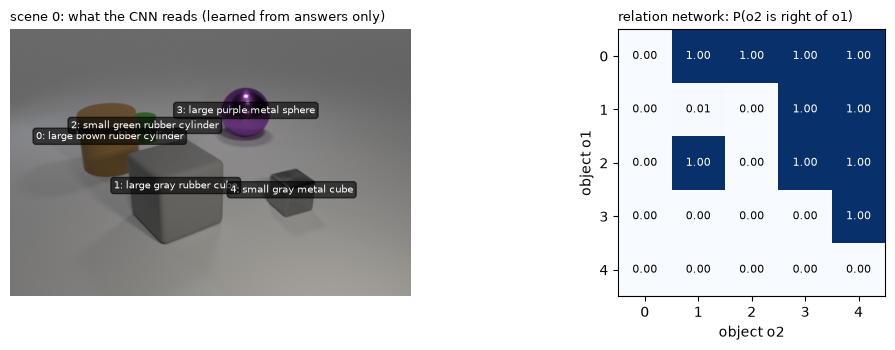

CLEVR's 'right' relation of this scene: {0: [1, 2, 3, 4], 1: [3, 4], 2: [1, 3, 4], 3: [4], 4: []}


In [12]:
s = local[0]
img = plt.imread(IMAGES / scenes[s]["image_filename"])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
axs[0].imshow(img)
with torch.no_grad():
    probs = net(torch.from_numpy(crops[s][:len(scenes[s]["objects"])]))
for i, ob in enumerate(scenes[s]["objects"]):
    x, y, _ = ob["pixel_coords"]
    label = " ".join(VALUES[a][int(probs[a][i].argmax())] for a in ("size", "color", "material", "shape"))
    axs[0].text(x, y, f"{i}: {label}", color="white", fontsize=7, ha="center",
                bbox=dict(boxstyle="round", fc="black", alpha=0.6))
axs[0].axis("off")
axs[0].set_title(f"scene {s}: what the CNN reads (learned from answers only)", fontsize=9, loc="left")
n = len(scenes[s]["objects"])
with torch.no_grad():
    right = relnet(positions([scenes[s]]))[0, DIRS.index("right"), :n, :n]
axs[1].imshow(right, cmap="Blues", vmin=0, vmax=1)
for o1 in range(n):
    for o2 in range(n):
        axs[1].text(o2, o1, f"{right[o1, o2]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if right[o1, o2] > 0.5 else "black")
axs[1].set_xticks(range(n)); axs[1].set_yticks(range(n))
axs[1].set_xlabel("object o2"); axs[1].set_ylabel("object o1")
axs[1].set_title("relation network: P(o2 is right of o1)", fontsize=9, loc="left")
plt.tight_layout()
plt.show()
print("CLEVR's 'right' relation of this scene:", {o1: o2s for o1, o2s in enumerate(scenes[s]["relationships"]["right"])})

### One question, step by step

How the trained sLTN answers one validation question about the scene above, with the networks of run 2 (attributes and relations both learned). The question: *"What is the thing in front of the small metallic object made of?"*

The idea to keep in mind: **nothing is decided until the very end.** Each step computes a truth value for *every* object (or every pair of objects), and the next step combines them. Only the last step picks an answer. Each step below shows sLTN's result and the same numbers computed by hand, to show that it is nothing more than products (for `and`) and maxima (for `exists`).

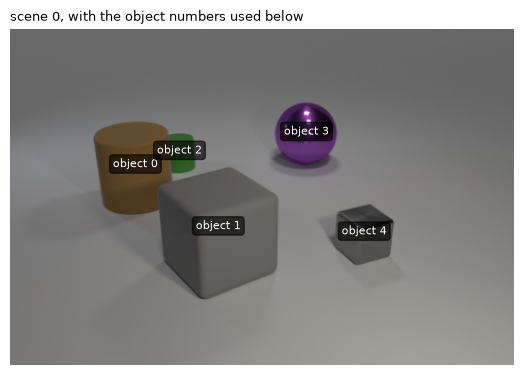

question: What is the thing in front of the small metallic object made of?
answer in the dataset: rubber

program:
   0: scene   <- []
   1: filter_size small   <- [0]
   2: filter_material metal   <- [1]
   3: unique   <- [2]
   4: relate front   <- [3]
   5: unique   <- [4]
   6: query_material   <- [5]

formula, free in q and in the candidate material km:
   exists o2: (((Present(q, o2) & exists o1: ((Present(q, o1) & IsC(color(x[q, o1]), c0[q]) &
   IsZ(size(x[q, o1]), z0[q]) & IsM(material(x[q, o1]), m0[q]) & IsS(shape(x[q, o1]), s0[q])) &
   R0(q, o1, o2))) & IsC(color(x[q, o2]), c1[q]) & IsZ(size(x[q, o2]), z1[q]) & IsM(material(x[q, o2]), m1[q])
   & IsS(shape(x[q, o2]), s1[q])) & IsM(material(x[q, o2]), km))


In [13]:
import textwrap
from clevr_sltn import PARAM, _Builder, by_name, compile_question, family_tensors, make_signature, scene_arrays
from e1_images import embed_scenes, ground, make_interp

s = local[0]
questions = json.load(open(DATA / "questions" / "CLEVR_val_questions.json"))["questions"]
q = next(q for q in questions if q["image_index"] == s and q["question"].startswith("What is the thing in front of"))
c = compile_question(q)

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.imshow(plt.imread(IMAGES / scenes[s]["image_filename"]))
for i, ob in enumerate(scenes[s]["objects"]):
    x, y, _ = ob["pixel_coords"]
    ax.text(x, y, f"object {i}", color="white", fontsize=8, ha="center",
            bbox=dict(boxstyle="round", fc="black", alpha=0.6))
ax.axis("off")
ax.set_title(f"scene {s}, with the object numbers used below", fontsize=9, loc="left")
plt.show()
print(f"question: {q['question']}\nanswer in the dataset: {q['answer']}\n")
print("program:")
for i, node in enumerate(q["program"]):
    value = f" {node['value_inputs'][0]}" if node["value_inputs"] else ""
    print(f"   {i}: {node['function']}{value}   <- {node['inputs']}")
print(f"\nformula, free in q and in the candidate material km:")
wrapped = textwrap.fill(c.body.replace(", ", ",\u00a0"), 110, initial_indent="   ", subsequent_indent="   ")
print(wrapped.replace("\u00a0", " "))   # break lines only between atoms

**Reading the formula.** Each part of the question becomes a part of the formula:

| In the question | Program nodes | In the formula |
|---|---|---|
| "the small metallic object" | 0–3 | object variable `o1`, with filter slot 0: `Present(q, o1)` and one atom per attribute, `IsZ(size(x[q, o1]), z0[q])` for the size, `IsM(material(x[q, o1]), m0[q])` for the material, ... |
| "the thing in front of it" | 4–5 | object variable `o2`, and `exists o1: (... & R0(q, o1, o2))`; slot 1 is empty ("thing" names no attribute) |
| "made of?" | 6 | `IsM(material(x[q, o2]), km)`: is o2's material the candidate `km`? |

**Free variables.** The formula is *free in* `q` and `km`: they aren't bound by a quantifier, so the result has one truth value for each of their values.
- `q` runs over a batch of questions with the same program: 80 per family in training, one here. The same formula serves every question of the family; only the slots and the direction of `R0` change.
- `km` runs over the candidate answers, rubber and metal: the formula gets a truth value for each, and the answer is the most true one.

In [14]:
(_, t), = family_tensors([q]).values()            # the question's words and answer, as in training
t["scene"] = torch.zeros(1, dtype=torch.long)      # the question's scene is scene 0 of the arrays below
attr, present, rel = scene_arrays([scenes[s]])
sd = dict(present=present, rel=rel, pos=positions([scenes[s]]), crops=torch.from_numpy(crops[s])[None])
sig = make_signature()
it = make_interp(sig, net)
with torch.no_grad():
    ground(it, c, t, torch.zeros(1, dtype=torch.long), embed_scenes(net, sd["crops"], sd["present"]), sd, relnet)

print("the question's words, as fixed vectors:")
for k in range(c.n_slots):
    for a in ATTRS:
        v = t["slots"][a][k, 0]
        named = f"one-hot of '{VALUES[a][int(v.argmax())]}'" if v.sum() == 1 else "all ones (the question names no value)"
        print(f"   {PARAM[a]}{k}[q] = {[int(e) for e in v]}   {named}")
direction = DIRS[int(t["rel"][0, 0])]
print(f"   R0: the relation network's output for '{direction}'")

n = len(scenes[s]["objects"])
with torch.no_grad():
    probs = net(torch.from_numpy(crops[s][:n]))
print("\nthe objects through the CNN: the size and material distributions (what the formula uses)")
print(f"{'object':>6s} | {'P(small)':>8s} {'P(large)':>8s} | {'P(rubber)':>9s} {'P(metal)':>8s} | most probable values")
for i in range(n):
    best = " ".join(VALUES[a][int(probs[a][i].argmax())] for a in ATTRS)
    print(f"{i:6d} | {float(probs['size'][i, 0]):8.4f} {float(probs['size'][i, 1]):8.4f} | "
          f"{float(probs['material'][i, 0]):9.4f} {float(probs['material'][i, 1]):8.4f} | {best}")

the question's words, as fixed vectors:
   c0[q] = [1, 1, 1, 1, 1, 1, 1, 1]   all ones (the question names no value)
   z0[q] = [1, 0]   one-hot of 'small'
   m0[q] = [0, 1]   one-hot of 'metal'
   s0[q] = [1, 1, 1]   all ones (the question names no value)
   c1[q] = [1, 1, 1, 1, 1, 1, 1, 1]   all ones (the question names no value)
   z1[q] = [1, 1]   all ones (the question names no value)
   m1[q] = [1, 1]   all ones (the question names no value)
   s1[q] = [1, 1, 1]   all ones (the question names no value)
   R0: the relation network's output for 'front'

the objects through the CNN: the size and material distributions (what the formula uses)
object | P(small) P(large) | P(rubber) P(metal) | most probable values
     0 |   0.0000   1.0000 |    1.0000   0.0000 | brown large rubber cylinder
     1 |   0.0000   1.0000 |    1.0000   0.0000 | gray large rubber cube
     2 |   1.0000   0.0000 |    1.0000   0.0000 | green small rubber cylinder
     3 |   0.0000   1.0000 |    0.0000   1.0000

**The grounding.**
- **The question's words** are fixed vectors: "small" is the one-hot `z0[q]` = (1, 0) over (small, large), "metallic" is `m0[q]` = (0, 1) over (rubber, metal). The colour and shape slots are all ones, since the question names neither. Slot 1 is all ones everywhere.
- **The objects** go through the CNN, one crop each. Each head gives a **probability distribution**, not a class: the formula always works with these probabilities (the last column, the most probable values, is only for reading). After training they are almost one-hot, which is why they print as 0 and 1.
- **An atom is a dot product**, so it is a probability: `IsZ(size(x[q, o1]), z0[q])` = (P(small), P(large)) · (1, 0) = P(small). An all-ones slot gives P(gray) + P(red) + ... = 1: an atom the question doesn't name is always true.

In [15]:
ref = _Builder(q["program"]).unique(3)    # the formula of o1: "the small metallic object"
with torch.no_grad():
    a_sltn = by_name(it(sig.parse(ref)), ["q", "o1"])[0, :n]
a_hand = probs["size"][:, 0] * probs["material"][:, 1]       # Present = 1 for these objects; colour and shape atoms = 1

print("step (a): is o1 the small metallic object?  For every object at once.")
print(f"{'o1':>6s} | {'P(small)':>8s} x {'P(metal)':>8s} = {'by hand':>7s} | {'sLTN':>6s}")
for i in range(n):
    print(f"{i:6d} | {float(probs['size'][i, 0]):8.4f} x {float(probs['material'][i, 1]):8.4f} = "
          f"{float(a_hand[i]):7.4f} | {float(a_sltn[i]):6.4f}")

step (a): is o1 the small metallic object?  For every object at once.
    o1 | P(small) x P(metal) = by hand |   sLTN
     0 |   0.0000 x   0.0000 =  0.0000 | 0.0000
     1 |   0.0000 x   0.0000 =  0.0000 | 0.0000
     2 |   1.0000 x   0.0000 =  0.0000 | 0.0000
     3 |   0.0000 x   1.0000 =  0.0000 | 0.0000
     4 |   1.0000 x   1.0000 =  1.0000 | 1.0000


**Step (a).** `o1` is not one object but an axis: sLTN evaluates "o1 is small, metallic, and present" for all five objects at once, and gets five truth values. Object 4, the small gray metal cube, is true; the others are false (the large ones fail P(small), the rubber ones fail P(metal)). Nothing is selected yet: the result is a column of numbers, one per object, that the next steps use as weights.

In [16]:
with torch.no_grad():
    R0 = relnet(sd["pos"])[0, DIRS.index(direction), :n, :n]   # R0[o1, o2] = P(o2 is in front of o1)

print(f"R0(q, o1, o2) = P(o2 is in front of o1), for every pair (rows o1, columns o2):")
print("   o1 \\ o2 " + " ".join(f"{j:>7d}" for j in range(n)))
for i in range(n):
    print(f"{i:>9d}  " + " ".join(f"{float(R0[i, j]):7.4f}" for j in range(n)))

R0(q, o1, o2) = P(o2 is in front of o1), for every pair (rows o1, columns o2):
   o1 \ o2       0       1       2       3       4
        0   0.0017  1.0000  0.0000  0.0000  1.0000
        1   0.0000  0.0041  0.0000  0.0000  0.0002
        2   1.0000  1.0000  0.0016  0.0002  1.0000
        3   1.0000  1.0000  0.9974  0.0038  1.0000
        4   0.0000  0.9998  0.0000  0.0000  0.0056


**The relation.** `R0` is the relation network's *front* output for **every** pair of objects: a 5 × 5 table of probabilities. Many entries are high: for example, R0[2, 0] = 1, object 0 is in front of object 2. The relation alone doesn't know which row matters; step (c) combines it with (a).

In [17]:
obj = _Builder(q["program"]).unique(5)    # the formula of o2: "the thing in front of the small metallic object"
with torch.no_grad():
    c_sltn = by_name(it(sig.parse(obj)), ["q", "o2"])[0, :n]
weighted = a_hand[:, None] * R0                               # (a)(o1) x R0(o1, o2): rows o1, columns o2
c_hand = weighted.max(0).values                               # exists o1 = the max over the rows

print("(a)(o1) x R0(o1, o2): each row of R0 multiplied by o1's truth value in step (a)")
print("   o1 \\ o2 " + " ".join(f"{j:>7d}" for j in range(n)))
for i in range(n):
    print(f"{i:>9d}  " + " ".join(f"{float(weighted[i, j]):7.4f}" for j in range(n)))
print("\nstep (c): is o2 the thing in front of the small metallic object?  The max of each column:")
print(f"{'o2':>6s} | {'by hand':>7s} | {'sLTN':>6s}")
for j in range(n):
    print(f"{j:6d} | {float(c_hand[j]):7.4f} | {float(c_sltn[j]):6.4f}")

(a)(o1) x R0(o1, o2): each row of R0 multiplied by o1's truth value in step (a)
   o1 \ o2       0       1       2       3       4
        0   0.0000  0.0000  0.0000  0.0000  0.0000
        1   0.0000  0.0000  0.0000  0.0000  0.0000
        2   0.0000  0.0000  0.0000  0.0000  0.0000
        3   0.0000  0.0000  0.0000  0.0000  0.0000
        4   0.0000  0.9998  0.0000  0.0000  0.0056

step (c): is o2 the thing in front of the small metallic object?  The max of each column:
    o2 | by hand |   sLTN
     0 |  0.0000 | 0.0000
     1 |  0.9998 | 0.9998
     2 |  0.0000 | 0.0000
     3 |  0.0000 | 0.0000
     4 |  0.0056 | 0.0056


**Step (c): this is where (a) and the relation meet.** The formula asks, for every candidate `o2`: *is there an `o1` that is the small metallic object **and** has `o2` in front of it?*
1. **`and`** multiplies each row `o1` of `R0` by (a)(o1). Every row of an object that isn't small and metallic is multiplied by about 0 and vanishes, however high its entries: R0[2, 0] = 1 becomes 0. Only row 4 survives. This is the soft version of "take o1 = object 4", without ever choosing it.
2. **`exists o1`** takes the maximum of each column: the best `o1` for that `o2`.

The result: object 1, the large gray cube, is "the thing in front of the small metallic object" (0.9998). Object 4 keeps a small value, 0.0056: the formula doesn't exclude `o2 = o1`, and the network gives "object 4 is in front of itself" a small probability. Slot 1 (all ones) and `Present` don't change anything here.

In [18]:
with torch.no_grad():
    d_sltn = by_name(it(sig.parse(c.body)), ["q", "km"])[0]

print("step (d): for each candidate material km, is o2 made of km?  The max over o2:")
for k, v in enumerate(VALUES["material"]):
    per_o2 = c_hand * probs["material"][:, k]                  # (c)(o2) x P(o2's material = km)
    print(f"   km = {v:>6s}: " + "  ".join(f"o2={j}: {float(per_o2[j]):.4f}" for j in range(n))
          + f"  -> max {float(per_o2.max()):.4f} (sLTN {float(d_sltn[k]):.4f})")
print(f"\nanswer: the most true candidate, {VALUES['material'][int(d_sltn.argmax())]} (dataset: {q['answer']})")

step (d): for each candidate material km, is o2 made of km?  The max over o2:
   km = rubber: o2=0: 0.0000  o2=1: 0.9998  o2=2: 0.0000  o2=3: 0.0000  o2=4: 0.0000  -> max 0.9998 (sLTN 0.9998)
   km =  metal: o2=0: 0.0000  o2=1: 0.0000  o2=2: 0.0000  o2=3: 0.0000  o2=4: 0.0056  -> max 0.0056 (sLTN 0.0056)

answer: the most true candidate, rubber (dataset: rubber)


**Step (d): the answer.** For each candidate material, the formula asks *is there an `o2` that is the thing in front of the small metallic object **and** is made of that material?*: again a product, then a max over `o2`.
- *rubber*: through object 1, which is rubber: 0.9998.
- *metal*: only through object 4, which is metal but has just 0.0056 from step (c).

The answer is the candidate with the highest truth value, **rubber**, as in the dataset. This argmax over the candidates is the only decision in the whole computation.

**Why it is built this way.**
- **Nothing is chosen until the end**, so in training the gradient reaches every object and every pair, in proportion to how much it could have changed the answer. A hard choice ("o1 = object 4") would give no gradient to the objects not chosen.
- **The formula has no uniqueness check**: `exists` takes the best match. If two objects were small and metallic, step (c) would take the best of their rows.
- With outputs this close to one-hot, this soft computation gives the same answer as running the program on the most probable values. The two can differ only when the networks are unsure.

## 10. Findings

- **The answers are enough to learn the concepts from images.** With the relations given (run 1), the CNN reads colour, size, material and shape at 99.8–100% on validation objects, without a single attribute label, and the formulas answer 99.9% of the validation questions.
- **The relations can be learned too, together with the attributes** (run 2): 99.9–100% on validation pairs, with the attributes still at 99.8–100% and the answers at 99.8%.
- **Answers teach as much as labels when the objects are readable** (step 0, noise 1), and need more data when they are hard to read; with very noisy features, learning from answers stalls where labels still teach something.
- **Neither half of the questions is needed to bootstrap the other** (run 3): trained only on questions that involve a spatial relation, the two networks learn as well and as fast as in run 2.
- **Questions of families never trained on are answered as well as the trained ones** (run 3): 99.8–99.95% on the 29 families without a relate, since they are answered by composing the learned concepts in their formulas.

**Limits.**
- One seed per run.
- Where the objects are is given: the crops are cut at the scene file's positions, and the relation network reads those positions. Finding the objects in the image is not learned.
- The programs are given: no English is parsed.
- 48 × 48 crops sometimes include parts of neighbouring objects.
- The CLEVR paper's models are not a like-for-like comparison (they learn from pixels and text). The closest work is NS-CL (Mao et al., ICLR 2019), which also learns visual concepts from question–answer pairs, with a learned parser and executor; it reports 98.9% QA with 10% of the training data.

**Next:** more seeds; fewer training questions (how fast the concepts emerge); the CoGenT split (attribute combinations never seen together in training); and the case without relations.